<a href="https://colab.research.google.com/github/azaanmumtaz01-boop/handwritten-digit-recognition/blob/main/Copy_of_handwritten_digit_recognition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
print("handwritten digit recognition project")
print("project started successfully")

handwritten digit recognition project
project started successfully


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
print("numpy version:",np.__version__)
print("tensortflow version:",tf.__version__)

numpy version: 2.1.3
tensortflow version: 2.20.0


In [ ]:
from tensorflow.keras.datasets import mnist
(x_train,y_train),(x_test,y_test)=mnist.load_data()
print("training images:",x_train.shape)
print("training labels:",y_train.shape)

print("testing images:",x_test.shape)
print("testing labels:",y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
training images: (60000, 28, 28)
training labels: (60000,)
testing images: (10000, 28, 28)
testing labels: (10000,)


actual digit: 5


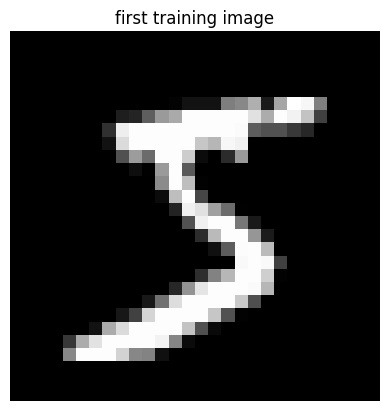

In [ ]:
plt.imshow(x_train[0],cmap='gray')
plt.title("first training image")
plt.axis('off')
print("actual digit:",y_train[0])

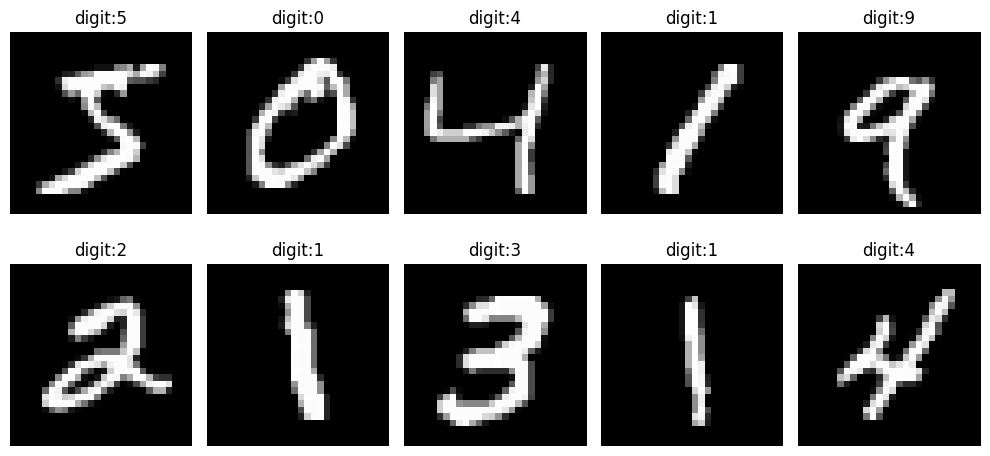

In [ ]:
plt.figure(figsize=(10,5))
for i in range(10):
  plt.subplot(2,5,i+1)
  plt.imshow(x_train[i],cmap='gray')
  plt.title(f"digit:{y_train[i]}")
  plt.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
x_train=x_train.astype("float32")/255.0
x_test=x_test.astype("float32")/255.0
print("training data prepared.")
print("testing data prepared.")

training data prepared.
testing data prepared.


In [ ]:
!pip install tensorflow

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Flatten , Dense
model = Sequential([
    Input(shape=(28,28)),
    Flatten(),
    Dense(128, activation = 'relu'),
    Dense(10, activation = 'softmax')
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
print("Model compiled successfully.")

Model compiled successfully.


In [ ]:
history = model.fit(
    x_train,
    y_train,
    epochs=5,
    validation_split=0.1
)

Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.7148 - loss: 1.2061 - val_accuracy: 0.8820 - val_loss: 0.5533
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8710 - loss: 0.5012 - val_accuracy: 0.9095 - val_loss: 0.3574
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8918 - loss: 0.3936 - val_accuracy: 0.9158 - val_loss: 0.3081
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9014 - loss: 0.3524 - val_accuracy: 0.9222 - val_loss: 0.2781
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9061 - loss: 0.3289 - val_accuracy: 0.9275 - val_loss: 0.2592


In [ ]:
test_loss,test_accuracy=model.evaluate(x_test,y_test)
print("test accuracy:",test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9139 - loss: 0.3038
test accuracy: 0.9139000177383423


In [ ]:
prediction=model.predict(x_test)
predicted_digit=np.argmax(prediction[0])
print("Predicted digit:",predicted_digit)
print("Actual digit:",y_test[0])

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Predicted digit: 7
Actual digit: 7


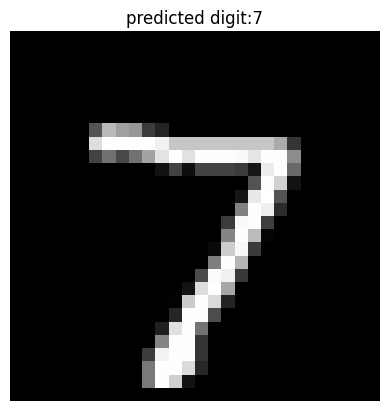

In [ ]:
plt.imshow(x_test[0],cmap='gray')
plt.title(f"predicted digit:{predicted_digit}")
plt.axis('off')
plt.show()

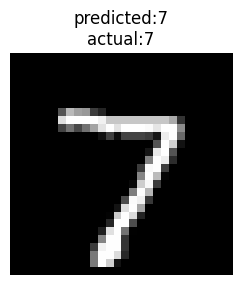

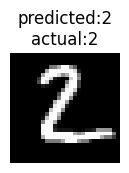

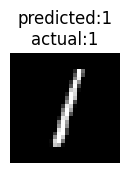

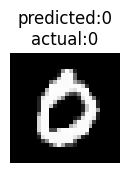

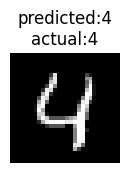

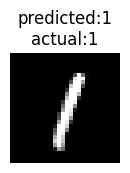

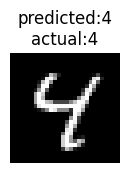

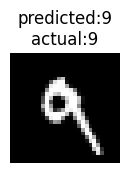

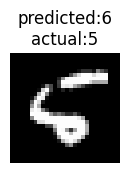

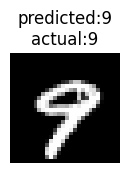

In [ ]:
plt.figure(figsize=(12,6))
for i in range(10):
  predicted = np.argmax(prediction[i])
  plt.subplot(2,5,i+1)
  plt.imshow(x_test[i],cmap='gray')
  plt.title(f"predicted:{predicted}\nactual:{y_test[i]}")
  plt.axis('off')
  plt.tight_layout()
  plt.show()


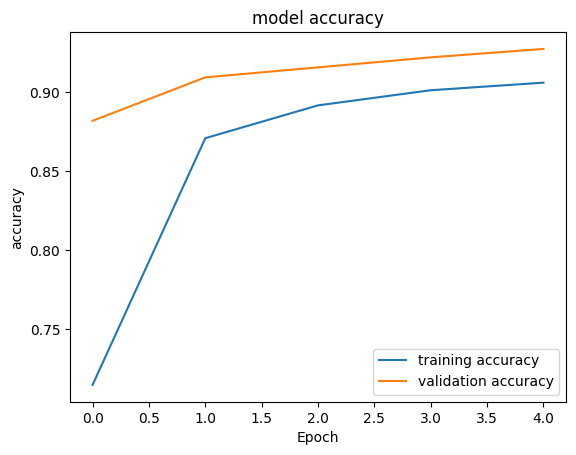

In [ ]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.xlabel('Epoch')
plt.ylabel('accuracy')
plt.legend(['training accuracy','validation accuracy'])
plt.show()

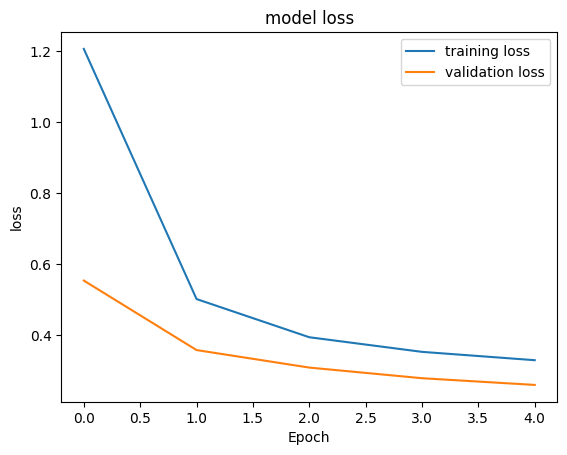

In [ ]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.xlabel('Epoch')
plt.ylabel('loss')
plt.legend(['training loss','validation loss'])
plt.show()